In [3]:
import numpy as np
import pandas as pd
from scipy.stats import kurtosis
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,f1_score

In [4]:
# 1. Carregando os CSVs brutos (Ajuste o caminho conforme a sua pasta)
caminho_normal = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_NORMAIS_1KHZ\\dados_valores_xyz_puro.csv"
caminho_fita   = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_FITA_1KHZ\\dados_valores_xyz_puro_fita.csv"

df_raw_normal = pd.read_csv(caminho_normal)
df_raw_fita   = pd.read_csv(caminho_fita)

# 2. Intervalos estáveis (em segundos) validados na fase de EDA
cortes_normal = {
    1: (20, 620),    # Velocidade 1 Normal
    2: (660, 1230),  # Velocidade 2 Normal
    3: (1270, 1780)  # Velocidade 3 Normal
}

cortes_fita = {
    1: (20, 580),    # Velocidade 1 com Fita
    2: (620, 1170),  # Velocidade 2 com Fita
    3: (1210, 1800)  # Velocidade 3 com Fita
}

print("Arquivos carregados com sucesso!")

Arquivos carregados com sucesso!


### 1.1. Definição da Tarefa e Contrato de Métricas
Antes de modelar, definimos formalmente os nossos objetivos e as métricas de sucesso:
1. **Tarefa Binária:** Classificar se a janela operacional é `Normal (0)` ou `Anomalia - Fita na Hélice (1)`.
2. **Tarefa Multiclasse:** Classificar as `6 Classes Físicas` do ventilador (`Vel 1 Normal`, `Vel 1 Fita`, `Vel 2 Normal`, `Vel 2 Fita`, `Vel 3 Normal`, `Vel 3 Fita`).
3. **Métrica Primária (Recall por Velocidade):** A acurácia global fica em segundo plano. O foco absoluto é garantir alto *Recall* da anomalia desmembrado por velocidade (para evitar deixar a `Vel 1 - Fita` passar sem alarme) e controlar a taxa de falsos alarmes nos dados normais.

In [5]:
def extrair_features_janelas_cego(df_bruto, cortes_vel, flag_anomalia, nome_estado, 
                                  segundos_janela=5, taxa_amostragem=1000, largura_bin_hz=10):
    """
    Fatia o dataset bruto em janelas temporais e extrai:
    1. Domínio do Tempo (9 variáveis): STD, Curtose e Pico nos eixos X, Y e Z (RMS removido por redundância).
    2. Domínio da Frequência (90 variáveis): FFT tratada com Hanning, dividida em blocos de 10 em 10 Hz (5 a 305 Hz).
    """
    N = int(segundos_janela * taxa_amostragem)
    janela_hanning = np.hanning(N)
    freqs_fft = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)
    limites_hz = np.arange(5, 305 + largura_bin_hz, largura_bin_hz)
    
    df = df_bruto.copy()
    df['segundo'] = np.arange(len(df)) // taxa_amostragem
    
    lista_features = []
    lista_gabarito = []
    
    for vel_num, (inicio_s, fim_s) in cortes_vel.items():
        recorte_vel = df[(df['segundo'] >= inicio_s) & (df['segundo'] < fim_s)]
        total_janelas = len(recorte_vel) // N
        
        for j in range(total_janelas):
            fatia = recorte_vel.iloc[j * N : (j + 1) * N]
            linha_feat = {}
            
            for eixo in ['x', 'y', 'z']:
                sinal = fatia[eixo].values
                sinal_zero = sinal - np.mean(sinal)
                
                # Domínio do Tempo (9 features sem RMS)
                linha_feat[f'std_{eixo}']  = np.std(sinal_zero, ddof=1)
                linha_feat[f'kurt_{eixo}'] = kurtosis(sinal_zero, fisher=True)
                linha_feat[f'pico_{eixo}'] = np.max(np.abs(sinal_zero))
                
                # Domínio da Frequência (FFT cega de 10 em 10 Hz)
                espectro = np.abs(np.fft.rfft(sinal_zero * janela_hanning)) * (4.0 / N)
                for k in range(len(limites_hz) - 1):
                    f_ini = limites_hz[k]
                    f_fim = limites_hz[k + 1]
                    masc = (freqs_fft >= f_ini) & (freqs_fft < f_fim)
                    linha_feat[f'fft_{f_ini:03d}_{f_fim:03d}Hz_{eixo}'] = np.max(espectro[masc])
            
            lista_features.append(linha_feat)
            lista_gabarito.append({
                'velocidade': vel_num,
                'anomalia': flag_anomalia,
                'estado_nome': nome_estado,
                'classe_completa': f'Vel {vel_num} - {nome_estado}'
            })
            
    return pd.DataFrame(lista_features), pd.DataFrame(lista_gabarito)

# Executando a extração definitiva com Janela de 5 Segundos
X_norm, gab_norm = extrair_features_janelas_cego(df_raw_normal, cortes_normal, 0, "Normal", segundos_janela=5)
X_fita, gab_fita = extrair_features_janelas_cego(df_raw_fita, cortes_fita, 1, "Fita na Hélice", segundos_janela=5)

# Adicionando rastreamento cronológico estrito
for df_g in [gab_norm, gab_fita]:
    df_g['idx_janela_classe'] = df_g.groupby('velocidade').cumcount()
    df_g['tempo_relativo_s'] = df_g['idx_janela_classe'] * 5

X_total = pd.concat([X_norm, X_fita], ignore_index=True)
meta_total = pd.concat([gab_norm, gab_fita], ignore_index=True)

print(f"Dataset consolidado gerado com sucesso: {X_total.shape[0]} janelas de 5 segundos.")

Dataset consolidado gerado com sucesso: 676 janelas de 5 segundos.


### 2.1. Ferramentas de Avaliação e Visualização
Antes de rodar os modelos, definimos duas ferramentas oficiais de avaliação para garantir que analisaremos todos os algoritmos sob a mesma ótica:
1. **`avaliar_modelo_detalhado`**: Gera o relatório de texto clássico (Acurácia, F1-Score, e Matriz). Agora ela inclui automaticamente o *Recall* (Taxa de Acerto na Anomalia) e o *Falso Alarme* (Erro nos dados Normais) desmembrados para as Velocidades 1, 2 e 3.
2. **`plotar_resultados_modelo`**: Cria um painel visual duplo para cada modelo. À esquerda, a Matriz de Confusão (Heatmap Azul). À direita, um gráfico de barras comparando o Recall (Laranja) e o Falso Alarme (Azul) por Velocidade, facilitando a identificação de onde o modelo falha (como a Vel 1).

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

def avaliar_modelo_detalhado(y_real, y_pred, velocidades=None, nome_modelo="Modelo"):
    """
    Exibe um relatório limpo em texto com métricas globais e desmembradas por velocidade.
    """
    print(f"==================================================")
    print(f" AVALIAÇÃO DO MODELO: {nome_modelo}")
    print(f"==================================================")
    print(f"Acurácia Global: {accuracy_score(y_real, y_pred)*100:.2f}%")
    print(f"F1-Score (Macro): {f1_score(y_real, y_pred, average='macro'):.4f}\n")
    
    print("Relatório de Classificação por Classe:")
    print(classification_report(y_real, y_pred))
    
    print("Matriz de Confusão:")
    print(confusion_matrix(y_real, y_pred))
    
    # Adição: Calcula o Recall e Falso Alarme por Velocidade se o vetor for fornecido
    if velocidades is not None:
        print("\n--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---")
        for v in [1, 2, 3]:
            m = (velocidades == v)
            
            anomalias_reais = ((y_real == 1) & m).sum()
            acertos_anomalia = ((y_pred == 1) & (y_real == 1) & m).sum()
            recall = (acertos_anomalia / anomalias_reais) if anomalias_reais > 0 else 0
            
            normais_reais = ((y_real == 0) & m).sum()
            falsos_alarmes = ((y_pred == 1) & (y_real == 0) & m).sum()
            fpr = (falsos_alarmes / normais_reais) if normais_reais > 0 else 0
            
            print(f"Vel {v}: Recall Anomalia {recall:7.1%} | Falso Alarme {fpr:7.1%}")
    print(f"==================================================\n")


def plotar_resultados_modelo(y_real, y_pred, velocidades, nome_modelo):
    """
    Gera um painel visual 1x2: Matriz de Confusão (Heatmap) e Gráfico de Barras de Desempenho.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Gráfico da Esquerda: Heatmap da Matriz de Confusão
    cm = confusion_matrix(y_real, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
                xticklabels=['Pred: Normal', 'Pred: Fita'], 
                yticklabels=['Real: Normal', 'Real: Fita'], cbar=False, annot_kws={"size": 14})
    axes[0].set_title(f"Matriz de Confusão\n{nome_modelo}", fontweight='bold', fontsize=12)
    
    # 2. Gráfico da Direita: Barras de Recall e FPR por Velocidade
    recalls = []
    fprs = []
    for v in [1, 2, 3]:
        m = (velocidades == v)
        vp = ((y_pred == 1) & (y_real == 1) & m).sum()
        fn = ((y_pred == 0) & (y_real == 1) & m).sum()
        fp = ((y_pred == 1) & (y_real == 0) & m).sum()
        vn = ((y_pred == 0) & (y_real == 0) & m).sum()
        
        rec = vp / (vp + fn) if (vp + fn) > 0 else 0
        fpr = fp / (fp + vn) if (fp + vn) > 0 else 0
        
        recalls.append(rec * 100)
        fprs.append(fpr * 100)
        
    x = np.arange(3)
    width = 0.35
    
    rects1 = axes[1].bar(x - width/2, recalls, width, label='Recall (Taxa de Acerto na Fita)', color='#d95f02', edgecolor='black')
    rects2 = axes[1].bar(x + width/2, fprs, width, label='Falso Alarme (Erro no Normal)', color='#1f77b4', edgecolor='black')
    
    axes[1].set_ylabel('Porcentagem (%)')
    axes[1].set_title('Desempenho Desmembrado por Velocidade', fontweight='bold', fontsize=12)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(['Velocidade 1', 'Velocidade 2', 'Velocidade 3'])
    axes[1].set_ylim(0, 119) # Espaço extra para as tags no topo das barras
    axes[1].legend(loc='upper left')
    axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)
    
    # Adicionando os números de porcentagem em cima de cada barra
    for rects in [rects1, rects2]:
        for rect in rects:
            height = rect.get_height()
            axes[1].annotate(f'{height:.1f}%',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 4),  # 4 pontos de offset vertical
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=10, fontweight='bold')
                        
    plt.tight_layout()
    plt.show()

Passo 3: A "Memória" do Ventilador (Autocorrelação)
O que é isso e por que importa?
Pense na previsão do tempo: se está chovendo agora (12h00), é quase certeza que 12h01 também estará chovendo. Mas e daqui a 1 semana? A chuva de hoje não ajuda a adivinhar a de semana que vem.
Com o ventilador é igual: uma janela de 5s é muito parecida com a próxima janela de 5s (porque a vibração e o calor do motor têm inércia). Se colocarmos a janela da 12h00 no Treino e a da 12h01 no Teste, o modelo de IA vai "colar" na prova apenas reconhecendo o padrão vizinho.

A Autocorrelação (ACF) mede quantos segundos leva para o ventilador "esquecer" o estado anterior, ditando quantas janelas precisaremos jogar fora (como "embargo") entre o Treino e o Teste.

In [7]:
from scipy.signal import detrend

def autocorr_lag(serie, lag):
    """
    FERRAMENTA DE MEMÓRIA (ACF):
    Mede a similaridade (de 0 a 1) entre uma janela e a sua vizinha 'lag' passos à frente.
    Removemos a tendência (detrend) para que o leve aquecimento natural do motor 
    não engane a matemática.
    """
    s = detrend(serie) 
    if np.std(s) == 0:
        return 0.0
    # Calcula a correlação entre a série original e ela mesma deslocada ('lag')
    return np.corrcoef(s[:-lag], s[lag:])[0, 1]

Agora vamos usar a ferramenta para investigar o nosso dataset. Vamos testar a memória do ventilador de 1 até 5 janelas de distância (5s até 25s de distância).

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

lags_para_testar = [1, 2, 3, 4, 5]
registros_acf = []

for cls, df_grupo in meta_total.groupby('classe_completa'):
    idx_grupo = df_grupo.index
    X_cls = X_total.loc[idx_grupo]
    
    # Avaliamos a memória de uma variável de tempo (std_y) e da variável global geral (PC1)
    std_y_vals = X_cls['std_y'].values
    pc1_vals = PCA(n_components=1, random_state=42).fit_transform(
        StandardScaler().fit_transform(X_cls)
    ).ravel()
    
    for lag in lags_para_testar:
        registros_acf.append({
            'Classe': cls,
            'Lag (Janelas de distância)': lag,
            'Lag (Segundos de distância)': lag * 5,
            '|ACF| std_y': abs(autocorr_lag(std_y_vals, lag)),
            '|ACF| Energia Global (PC1)': abs(autocorr_lag(pc1_vals, lag))
        })

df_acf = pd.DataFrame(registros_acf)
# Agrupando para ver a média geral de todas as classes
resumo_acf = df_acf.groupby(['Lag (Janelas de distância)', 'Lag (Segundos de distância)'])[['|ACF| std_y', '|ACF| Energia Global (PC1)']].mean().round(3)

print("=== MEMÓRIA DO VENTILADOR (Correlação entre Janelas Vizinhas) ===")
display(resumo_acf)

=== MEMÓRIA DO VENTILADOR (Correlação entre Janelas Vizinhas) ===


,,|ACF| std_y,|ACF| Energia Global (PC1)
Lag (Janelas de distância),Lag (Segundos de distância),,
1,5,0.545,0.481
2,10,0.557,0.607
3,15,0.355,0.482
4,20,0.379,0.379
5,25,0.348,0.437


Passo 4: Criando os Blocos e o "Fosso de Proteção" (Guarda)
A Lógica do Corte:
Imagine uma fita de vídeo contínua da Vel 1 Normal de 10 minutos. Vamos cortar essa fita em 10 blocos de 60 segundos.
Para ter certeza absoluta de que um bloco não tem nenhuma relação com o bloco seguinte, nós cortamos fora e jogamos no lixo os últimos 10 segundos de CADA bloco. Isso cria um "Fosso de Proteção" (Janela de Guarda) entre eles.

Desses 10 blocos (isolados por fossos), nós trancamos os Blocos 2 e 7 num cofre (o Teste) e usamos os outros 8 blocos para ensinar a IA (o Treino).


=== CONTAGEM DE JANELAS E BLOCOS POR CLASSE E PARTIÇÃO ===


particao,DESCARTADA_GUARDA,TESTE_TRANCADO,TREINO_CV,All
classe_completa,,,,
Vel 1 - Fita na Hélice,18,18,76,112
Vel 1 - Normal,18,20,82,120
Vel 2 - Fita na Hélice,18,18,74,110
Vel 2 - Normal,18,19,77,114
Vel 3 - Fita na Hélice,18,20,80,118
Vel 3 - Normal,18,16,68,102
All,108,111,457,676


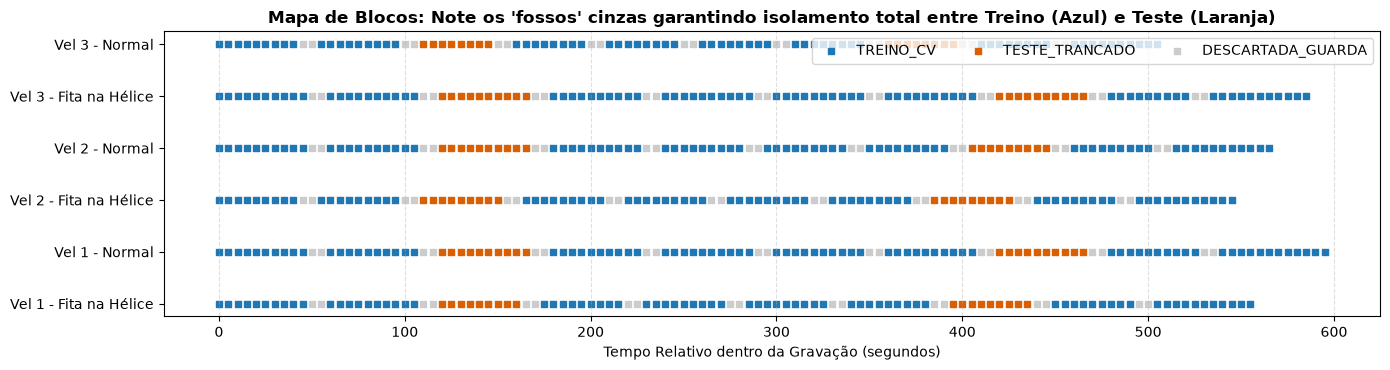

In [9]:
import matplotlib.pyplot as plt

# Parâmetros vitais da nossa metodologia
N_BLOCOS_POR_CLASSE = 10
JANELAS_GUARDA = 2          # 2 janelas descartadas = 10s de "fosso de proteção"
BLOCOS_TESTE_IDX = [2, 7]   # Guardaremos 20% pro Teste Final (longe um do outro no tempo)

# Preparando colunas de rastreio
meta_total['bloco_local'] = -1
meta_total['bloco_id'] = ""
meta_total['particao'] = "DESCARTADA_GUARDA"

for cls, df_grupo in meta_total.groupby('classe_completa'):
    # Pega os índices da classe em ordem cronológica
    indices_ordenados = df_grupo.sort_values('idx_janela_classe').index.values
    # Corta a "fita de vídeo" em 10 pedaços
    fatias_blocos = np.array_split(indices_ordenados, N_BLOCOS_POR_CLASSE)
    
    for b_num, inds_bloco in enumerate(fatias_blocos):
        # Cria o "fosso" jogando fora o final do bloco (exceto se for o último pedaço do ensaio)
        if b_num < (N_BLOCOS_POR_CLASSE - 1) and len(inds_bloco) > JANELAS_GUARDA:
            inds_uteis = inds_bloco[:-JANELAS_GUARDA]
        else:
            inds_uteis = inds_bloco
            
        meta_total.loc[inds_uteis, 'bloco_local'] = b_num
        meta_total.loc[inds_uteis, 'bloco_id'] = f"{cls}_B{b_num:02d}"
        
        # Decide quem vai pro Treino e quem vai pro Teste
        if b_num in BLOCOS_TESTE_IDX:
            meta_total.loc[inds_uteis, 'particao'] = "TESTE_TRANCADO"
        else:
            meta_total.loc[inds_uteis, 'particao'] = "TREINO_CV"

# Exibindo o resultado da divisão em Tabela
print("\n=== CONTAGEM DE JANELAS E BLOCOS POR CLASSE E PARTIÇÃO ===")
resumo_particao = pd.crosstab(meta_total['classe_completa'], meta_total['particao'], margins=True)
display(resumo_particao)

# Exibindo o resultado Visual (Mapa de Blocos)
fig, ax = plt.subplots(figsize=(14, 3.8))
cores_part = {'TREINO_CV': '#1f77b4', 'TESTE_TRANCADO': '#d95f02', 'DESCARTADA_GUARDA': '#cccccc'}
classes_ord = sorted(meta_total['classe_completa'].unique())

for i, cls in enumerate(classes_ord):
    sub = meta_total[meta_total['classe_completa'] == cls]
    for part, cor in cores_part.items():
        pts = sub[sub['particao'] == part]
        # Plota cada janela como um quadradinho no tempo-
        ax.scatter(pts['tempo_relativo_s'], np.repeat(i, len(pts)), c=cor, s=22, marker='s',
                   label=part if i == 0 else "")

ax.set_yticks(range(len(classes_ord)))
ax.set_yticklabels(classes_ord)
ax.set_xlabel("Tempo Relativo dentro da Gravação (segundos)")
ax.set_title(f"Mapa de Blocos: Note os 'fossos' cinzas garantindo isolamento total entre Treino (Azul) e Teste (Laranja)",
             fontweight='bold')
ax.legend(loc='upper right', ncol=3)
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Passo 5: Trancando o Cofre (Garantindo a Reprodutibilidade)
A Regra de Ouro do Machine Learning:
O conjunto de Teste deve simular o futuro. O modelo não pode olhar para ele de jeito nenhum durante o treinamento, nem para calcular médias, nem para ajustar o Scaler.
Para garantir isso e permitir que a banca reproduza o seu TCC de forma idêntica, vamos separar as duas tabelas fisicamente e salvá-las no computador (em .csv).

In [10]:
# 1. Separando fisicamente os DataFrames com base nas nossas marcações
mask_treino = (meta_total['particao'] == 'TREINO_CV').values
mask_teste  = (meta_total['particao'] == 'TESTE_TRANCADO').values

# Treino (80%) - Este será usado no KNN e Random Forest
X_train = X_total.loc[mask_treino].reset_index(drop=True)
meta_train = meta_total.loc[mask_treino].reset_index(drop=True)

# Teste (20%) - O COFRE. Só abriremos no final do projeto!
X_test_locked = X_total.loc[mask_teste].reset_index(drop=True)
meta_test_locked = meta_total.loc[mask_teste].reset_index(drop=True)

# 2. Salvando os arquivos em CSV no disco para a Banca e para auditoria
X_train.to_csv("X_train_5s_blocos.csv", index=False)
meta_train.to_csv("meta_train_5s_blocos.csv", index=False)
X_test_locked.to_csv("X_test_locked_5s_blocos.csv", index=False)
meta_test_locked.to_csv("meta_test_locked_5s_blocos.csv", index=False)

print("✅ Cofre trancado e arquivos salvos com sucesso!")
print(f"-> Treino: {X_train.shape[0]} janelas prontas para aprender.")
print(f"-> Teste:  {X_test_locked.shape[0]} janelas reservadas para a prova final.")

✅ Cofre trancado e arquivos salvos com sucesso!
-> Treino: 457 janelas prontas para aprender.
-> Teste:  111 janelas reservadas para a prova final.


Passo 6: Como treinar sem espiar a si mesmo? (Validação Cruzada por Blocos)
O Problema: Como vamos saber se o nosso KNN ficou bom se não podemos abrir o cofre de Teste agora?A Solução: Vamos simular mini-provas dentro do próprio Treino! Como temos 8 blocos de 60s para cada classe, vamos dividir esses 8 blocos em 4 partes (Folds). Cada parte terá exatamente 2 blocos de cada classe.
O modelo treina em 3 partes e faz a prova na 1 parte que sobrou. Ele repete isso 4 vezes. No final, teremos testado todas as janelas do treino sem que o modelo nunca tenha decorado a resposta.

## Validação Cruzada Estratificada por Blocos (`StratifiedGroupKFold`)
Para avaliar nossos modelos no conjunto de Treino sem risco de sobreajuste (*overfitting*), utilizamos a validação cruzada. 
* **Por que `Group`?** Garante que todas as janelas de um mesmo bloco de 60s caiam juntas (ou todas no treino do fold, ou todas na validação).
* **Por que `Stratified`?** Garante que todos os 4 folds (dobras) tenham exatamente a mesma proporção das 6 classes do ventilador. Se não usássemos isso, o sorteio aleatório poderia criar um fold sem nenhuma janela da `Vel 1 - Fita`, quebrando a nossa avaliação

In [11]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Extraindo rótulos e grupos do nosso conjunto de Treino
y_6_train = meta_train['classe_completa'].values
y_bin_train = meta_train['anomalia'].values
grupos_train = meta_train['bloco_id'].values

# Criando o divisor de Folds (4 partes)
sgkf = StratifiedGroupKFold(n_splits=4)

# Geramos a lista exata de quais índices vão para o Treino e quais vão para a Validação em cada um dos 4 testes.
# PASSAMOS A CLASSE COMPLETA (y_6_train) para o split, forçando ele a balancear as 6 velocidades.
cv_folds = list(sgkf.split(X_train, y_6_train, groups=grupos_train))

# Auditoria: Vamos conferir se o Fold 0 realmente ficou perfeitamente balanceado
treino_idx, val_idx = cv_folds[0]

print("=== AUDITORIA DO FOLD 0 (Validação Cruzada) ===")
print(f"Tamanho do Treino no Fold 0: {len(treino_idx)} janelas")
print(f"Tamanho da Validação no Fold 0: {len(val_idx)} janelas\n")

# Contando quantos blocos únicos caíram na validação para cada classe
blocos_na_val = meta_train.loc[val_idx].groupby('classe_completa')['bloco_id'].nunique()
print("Quantidade de Blocos na Validação por Classe (Devem ser exatos 2 blocos para cada):")
print(blocos_na_val)

=== AUDITORIA DO FOLD 0 (Validação Cruzada) ===
Tamanho do Treino no Fold 0: 343 janelas
Tamanho da Validação no Fold 0: 114 janelas

Quantidade de Blocos na Validação por Classe (Devem ser exatos 2 blocos para cada):
classe_completa
Vel 1 - Fita na Hélice    2
Vel 1 - Normal            2
Vel 2 - Fita na Hélice    2
Vel 2 - Normal            2
Vel 3 - Fita na Hélice    2
Vel 3 - Normal            2
Name: bloco_id, dtype: int64


Passo 7: A Escada de Complexidade (E o Segredo do Pipeline)
Não adianta usar um canhão para matar uma mosca. Na Engenharia, nós começamos com soluções estúpidas e vamos subindo a régua até a solução complexa (KNN/Random Forest).

Além disso, usaremos o Pipeline.O que é o Pipeline? Se você aplicar o StandardScaler na tabela de Treino inteira ANTES de cortar os 4 folds, a média matemática das janelas da validação vai "vazar" e contaminar o Treino. O Pipeline é um robô que garante que o Scaler será recalculado do zero dentro de cada mini-prova, usando apenas os dados de estudo daquela rodada.

### 3.2. Definição da Escada de Modelos e Execução da Validação Cruzada
Para testarmos o impacto das features de Tempo vs. 99 Features, criamos um dicionário simulando a "escada de complexidade". 

**Blindagem Anti-Vazamento:** Todos os modelos estão dentro de um `Pipeline`. Isso garante que o `StandardScaler` aplique a padronização apenas usando a média e o desvio da "mini-prova" de treino em execução, evitando que as métricas do teste contaminem o modelo.

Usamos a função `cross_val_predict` rodando nos nossos `cv_folds` (que garantem que janelas de um mesmo bloco de 60s caiam juntas, isolando-as da validação).

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict

# 1. Separando o vetor de velocidades e as features estritas de TEMPO (para os baselines)
vels_treino = meta_train['velocidade'].values
cols_tempo = [c for c in X_train.columns if not c.startswith('fft_')]
X_train_tempo = X_train[cols_tempo]

# 2. Dicionário da Escada de Complexidade
modelos = {
    # Nível 0 e 1: Usam APENAS as 9 variáveis de Tempo
    "N0: Chute Ingênuo (Tempo)": (
        Pipeline([('scaler', StandardScaler()), ('clf', DummyClassifier(strategy='most_frequent'))]),
        X_train_tempo
    ),
    "N1: Regressão Logística (Tempo)": (
        Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))]),
        X_train_tempo
    ),
    "N1: Árvore Rasa depth=2 (Tempo)": (
        Pipeline([('scaler', StandardScaler()), ('clf', DecisionTreeClassifier(max_depth=2, random_state=42))]),
        X_train_tempo
    ),
    
    # Nível 2: Usam todas as 99 Features (Tempo + FFT)
    "N2: KNN k=5 (99 Features)": (
        Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))]),
        X_train
    ),
    "N2: Random Forest (99 Features)": (
        Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]),
        X_train
    )
}

# 3. Executando a Validação Cruzada (Mini-provas) para todos os modelos do dicionário
print("Executando Validação Cruzada por Blocos (Out-of-Fold) para os 5 modelos...")
resultados_predicoes = {}

for nome, (pipeline, X_dados) in modelos.items():
    # cv_folds é a lista que criamos no Passo 6 usando o StratifiedGroupKFold
    y_pred_oof = cross_val_predict(pipeline, X_dados, y_bin_train, cv=cv_folds)
    resultados_predicoes[nome] = y_pred_oof
    
print("Predições concluídas! Dados prontos para visualização e avaliação.")

Executando Validação Cruzada por Blocos (Out-of-Fold) para os 5 modelos...
Predições concluídas! Dados prontos para visualização e avaliação.


### 3.3. Avaliação Visual dos Modelos
Agora pegamos o "gabarito" da validação cruzada (`y_pred_oof`) gerado por cada modelo e repassamos para as nossas duas ferramentas de avaliação criadas na Célula 3.1.
Isso gerará, para cada algoritmo, o laudo em texto e os dois gráficos combinados (Matriz e Gráfico de Barras).

 AVALIAÇÃO DO MODELO: N0: Chute Ingênuo (Tempo)
Acurácia Global: 50.33%
F1-Score (Macro): 0.3348

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       227
           1       0.50      1.00      0.67       230

    accuracy                           0.50       457
   macro avg       0.25      0.50      0.33       457
weighted avg       0.25      0.50      0.34       457

Matriz de Confusão:
[[  0 227]
 [  0 230]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme  100.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme  100.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme  100.0%



c:\Users\santo\OneDrive\Área de Trabalho\TCC\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\santo\OneDrive\Área de Trabalho\TCC\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\santo\OneDrive\Área de Trabalho\TCC\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

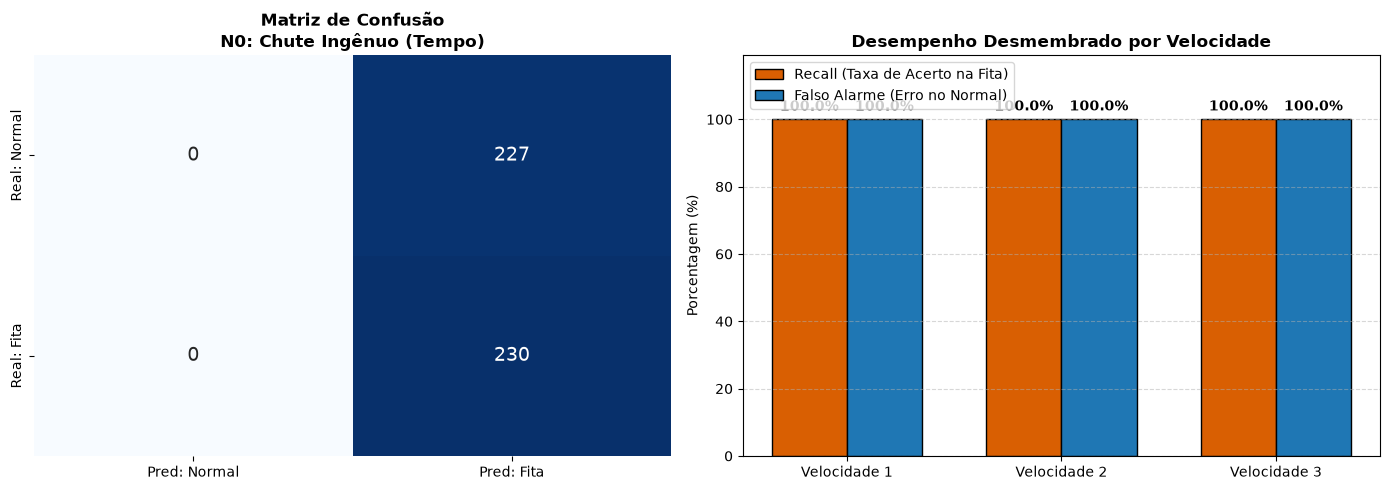




 AVALIAÇÃO DO MODELO: N1: Regressão Logística (Tempo)
Acurácia Global: 87.53%
F1-Score (Macro): 0.8747

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       0.83      0.95      0.88       227
           1       0.94      0.80      0.87       230

    accuracy                           0.88       457
   macro avg       0.88      0.88      0.87       457
weighted avg       0.88      0.88      0.87       457

Matriz de Confusão:
[[215  12]
 [ 45 185]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia   40.8% | Falso Alarme    1.2%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme   16.2%



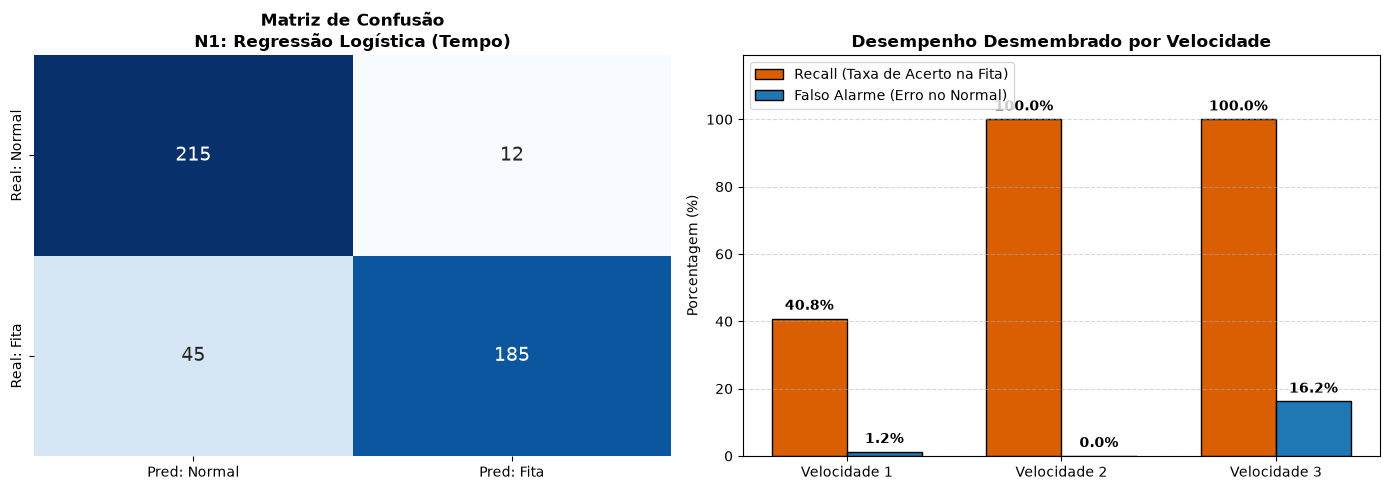




 AVALIAÇÃO DO MODELO: N1: Árvore Rasa depth=2 (Tempo)
Acurácia Global: 83.37%
F1-Score (Macro): 0.8293

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       227
           1       1.00      0.67      0.80       230

    accuracy                           0.83       457
   macro avg       0.87      0.83      0.83       457
weighted avg       0.88      0.83      0.83       457

Matriz de Confusão:
[[227   0]
 [ 76 154]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia    0.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%



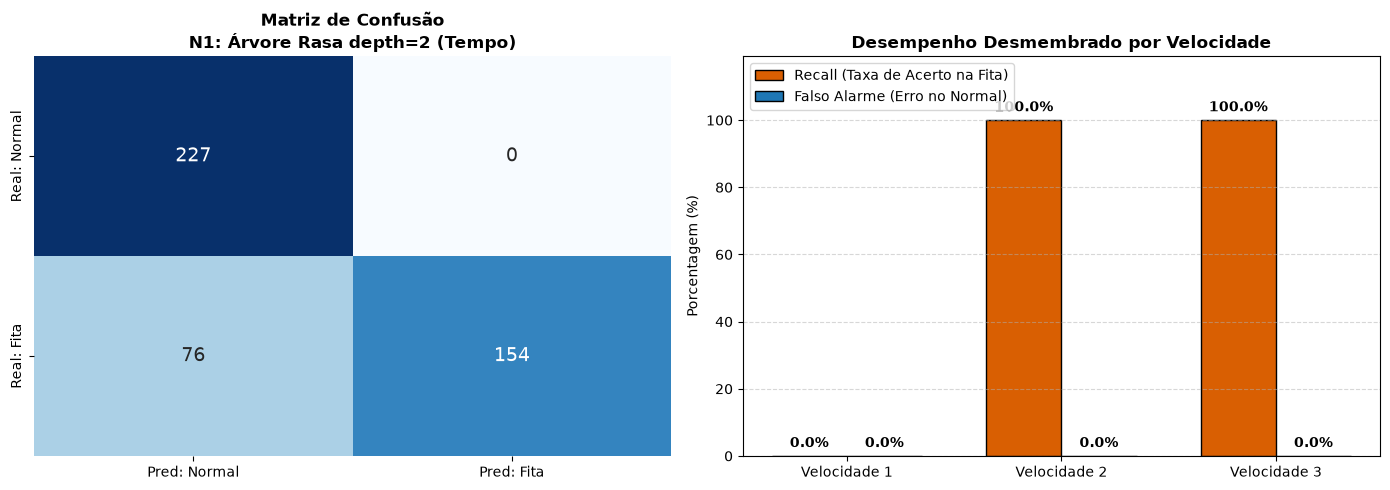




 AVALIAÇÃO DO MODELO: N2: KNN k=5 (99 Features)
Acurácia Global: 100.00%
F1-Score (Macro): 1.0000

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       227
           1       1.00      1.00      1.00       230

    accuracy                           1.00       457
   macro avg       1.00      1.00      1.00       457
weighted avg       1.00      1.00      1.00       457

Matriz de Confusão:
[[227   0]
 [  0 230]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%



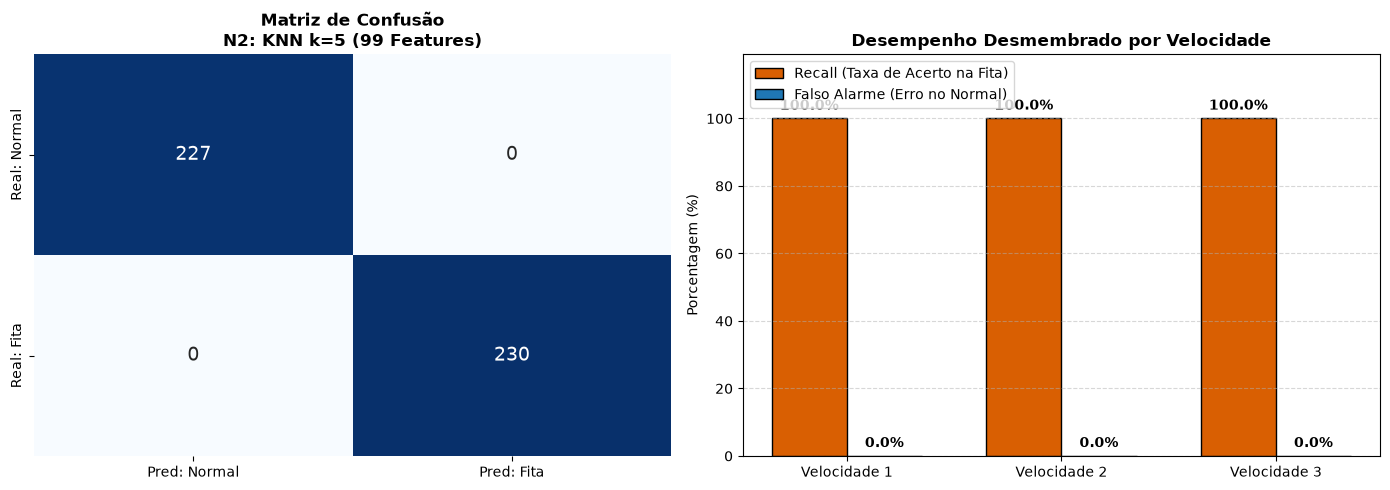




 AVALIAÇÃO DO MODELO: N2: Random Forest (99 Features)
Acurácia Global: 100.00%
F1-Score (Macro): 1.0000

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       227
           1       1.00      1.00      1.00       230

    accuracy                           1.00       457
   macro avg       1.00      1.00      1.00       457
weighted avg       1.00      1.00      1.00       457

Matriz de Confusão:
[[227   0]
 [  0 230]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%



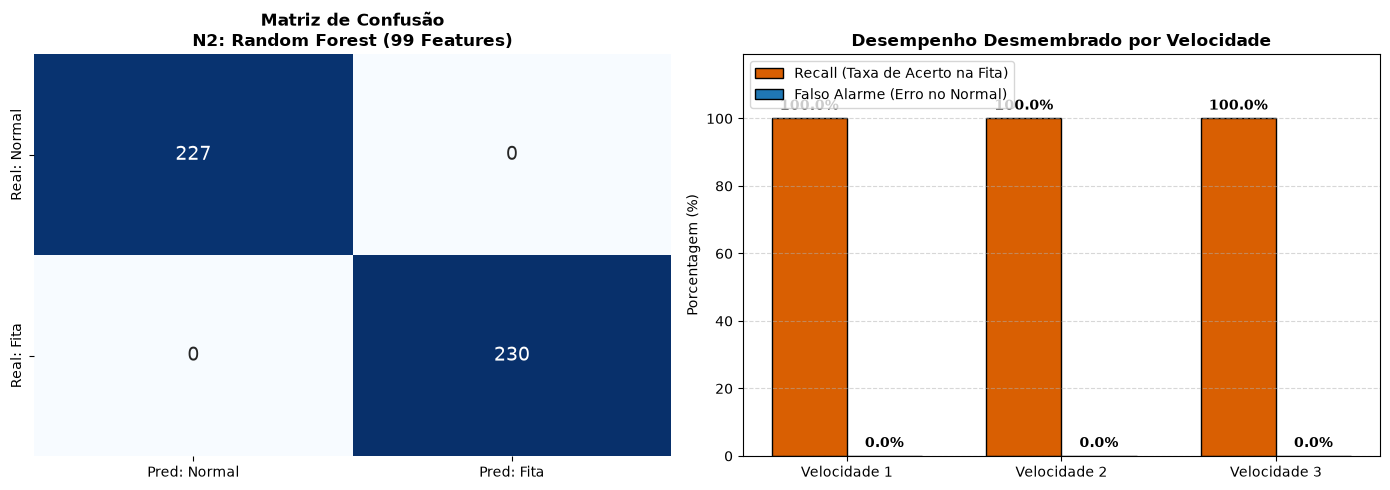

In [13]:
# 4. Avaliando os resultados: Iteramos sobre as respostas geradas e acionamos nossas ferramentas
for nome, y_pred in resultados_predicoes.items():
    
    # Imprime o texto no terminal (incluindo o Recall extraído da função customizada)
    avaliar_modelo_detalhado(y_real=y_bin_train, 
                             y_pred=y_pred, 
                             velocidades=vels_treino, 
                             nome_modelo=nome)
    
    # Desenha o painel gráfico duplo (Matriz Azul + Barras)
    plotar_resultados_modelo(y_real=y_bin_train, 
                             y_pred=y_pred, 
                             velocidades=vels_treino, 
                             nome_modelo=nome)
    
    # Uma linha de espaço visual para separar os modelos no Jupyter
    print("\n\n")

3.3. Avaliação de Recall e Falso Alarme Desmembrados por Velocidade
Esta célula aplica a função sobre as predições que já fizemos no Nível 0, 1 e 2, desmascarando em qual regime a Regressão Logística e a Árvore Rasa falharam.

In [14]:
def relatorio_recall_por_velocidade(y_real, dict_predicoes, velocidades):
    """
    Desmembra a avaliação para provar se a fita está passando despercebida 
    na Velocidade 1 (baixa energia).
    """
    print("==========================================================")
    print(" RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE")
    print("==========================================================")
    
    for nome_modelo, y_pred in dict_predicoes.items():
        print(f"\n--- {nome_modelo} ---")
        for v in [1, 2, 3]:
            # Máscara para isolar apenas a velocidade atual
            m = (velocidades == v)
            
            # Recall (Taxa de Acerto na Anomalia): VP / (VP + FN)
            anomalias_reais = ((y_real == 1) & m).sum()
            acertos_anomalia = ((y_pred == 1) & (y_real == 1) & m).sum()
            recall = (acertos_anomalia / anomalias_reais) if anomalias_reais > 0 else 0
            
            # FPR (Taxa de Falso Alarme no Normal): FP / (FP + VN)
            normais_reais = ((y_real == 0) & m).sum()
            falsos_alarmes = ((y_pred == 1) & (y_real == 0) & m).sum()
            fpr = (falsos_alarmes / normais_reais) if normais_reais > 0 else 0
            
            print(f"Vel {v}: Recall Anomalia {recall:7.1%} | Falso Alarme {fpr:7.1%}")

# Extraindo o vetor de velocidades do nosso treino
vels_treino = meta_train['velocidade'].values

# Rodando o relatório nas predições geradas na célula 3.2
relatorio_recall_por_velocidade(y_bin_train, resultados_predicoes, vels_treino)

 RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE

--- N0: Chute Ingênuo (Tempo) ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme  100.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme  100.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme  100.0%

--- N1: Regressão Logística (Tempo) ---
Vel 1: Recall Anomalia   40.8% | Falso Alarme    1.2%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme   16.2%

--- N1: Árvore Rasa depth=2 (Tempo) ---
Vel 1: Recall Anomalia    0.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%

--- N2: KNN k=5 (99 Features) ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%

--- N2: Random Forest (99 Features) ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
V

3.4. Estudo de Ablação (Testando KNN e RF sem a FFT) e Stump std_y
Vamos descobrir se precisamos mesmo das 99 features. Treinaremos os modelos complexos utilizando apenas as 9 variáveis de tempo, e adicionaremos o Stump (uma árvore de apenas 1 nó que tomará a decisão baseada unicamente no limite global do std_y).

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict

# Isolando as variáveis de interesse
X_train_tempo = X_train[[c for c in X_train.columns if not c.startswith('fft_')]]
X_train_std_y = X_train[['std_y']] # Apenas a coluna std_y para o Stump

modelos_ablacao = {
    "ABL: Stump (Apenas std_y, depth=1)": (
        Pipeline([('scaler', StandardScaler()), ('clf', DecisionTreeClassifier(max_depth=1, random_state=42))]),
        X_train_std_y
    ),
    "ABL: KNN k=5 (SOMENTE TEMPO - 9 feats)": (
        Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))]),
        X_train_tempo
    ),
    "ABL: Random Forest (SOMENTE TEMPO - 9 feats)": (
        Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]),
        X_train_tempo
    )
}

resultados_ablacao = {}

# Executando Validação Cruzada OOF
for nome, (pipeline, X_dados) in modelos_ablacao.items():
    y_pred_oof = cross_val_predict(pipeline, X_dados, y_bin_train, cv=cv_folds)
    resultados_ablacao[nome] = y_pred_oof

# Avaliando Acurácia Global e F1
for nome, y_pred in resultados_ablacao.items():
    avaliar_modelo_detalhado(y_bin_train, y_pred, nome_modelo=nome)

# Avaliando onde os modelos de ablação erraram
relatorio_recall_por_velocidade(y_bin_train, resultados_ablacao, vels_treino)

 AVALIAÇÃO DO MODELO: ABL: Stump (Apenas std_y, depth=1)
Acurácia Global: 83.37%
F1-Score (Macro): 0.8293

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       227
           1       1.00      0.67      0.80       230

    accuracy                           0.83       457
   macro avg       0.87      0.83      0.83       457
weighted avg       0.88      0.83      0.83       457

Matriz de Confusão:
[[227   0]
 [ 76 154]]

 AVALIAÇÃO DO MODELO: ABL: KNN k=5 (SOMENTE TEMPO - 9 feats)
Acurácia Global: 96.72%
F1-Score (Macro): 0.9672

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       227
           1       0.96      0.97      0.97       230

    accuracy                           0.97       457
   macro avg       0.97      0.97      0.97       457
weighted avg       0.97      0.97      0.97       457

Matriz

### 4. Testes Anti-Ilusão e Viés de Sessão (Stress Testing)
Resultados de 100% de acurácia acendem um alerta na Ciência de Dados: o modelo aprendeu a física real do defeito ou decorou uma coincidência do nosso teste? 
Para provar a validade do nosso modelo (Random Forest baseada apenas nas 9 variáveis de Tempo), executaremos três testes implacáveis:
1. **Sonda da Frequência Fundamental (1X):** Verifica se o modelo está roubando ao olhar apenas para a diferença de RPM entre os motores frio e quente.
2. **Divisão Cronológica Severa (Deriva Térmica):** Treina no início do ensaio e testa no final, forçando o modelo a lidar com o aquecimento gradual da estrutura.
3. **Embaralhamento de Rótulos por Bloco (Sanity Check):** Destrói a correlação real entre os dados e o gabarito. Se o modelo continuar acertando, há vazamento temporal. Ele **precisa** cair para ~50%.

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Vamos isolar apenas as janelas da Velocidade 1
mask_v1 = (meta_train['velocidade'] == 1).values
y_v1 = y_bin_train[mask_v1]

# Extraímos APENAS as features da FFT que cobrem a rotação do motor na Vel 1 (5 a 15 Hz)
cols_rpm_v1 = ['fft_005_015Hz_x', 'fft_005_015Hz_y', 'fft_005_015Hz_z']
X_rpm_v1 = X_train.loc[mask_v1, cols_rpm_v1]

# Treinamos uma Árvore simples apenas com o giro do motor
sonda_rpm = DecisionTreeClassifier(max_depth=2, random_state=42)
sonda_rpm.fit(X_rpm_v1, y_v1)
y_pred_sonda = sonda_rpm.predict(X_rpm_v1)

acc_sonda = accuracy_score(y_v1, y_pred_sonda) * 100

print("==========================================================")
print(" TESTE 1: SONDA DO GIRO DO MOTOR (Viés de Temperatura)")
print("==========================================================")
print(f"Acurácia da Sonda (Apenas {cols_rpm_v1}): {acc_sonda:.2f}%")
if acc_sonda > 95:
    print("⚠️ ALERTA: A diferença de RPM sozinha separa as classes. Risco de viés de sessão!")
else:
    print("✅ SUCESSO: A rotação sozinha não basta. O modelo principal deve estar usando a vibração física!")
print("==========================================================\n")

 TESTE 1: SONDA DO GIRO DO MOTOR (Viés de Temperatura)
Acurácia da Sonda (Apenas ['fft_005_015Hz_x', 'fft_005_015Hz_y', 'fft_005_015Hz_z']): 91.14%
✅ SUCESSO: A rotação sozinha não basta. O modelo principal deve estar usando a vibração física!



#### 4.2. Teste 2: Divisão Cronológica (Resiliência à Deriva Térmica)
Em vez de sortear os blocos de Treino e Teste espalhados no tempo, vamos simular o pior cenário industrial:
* **Treino:** Os primeiros 8 blocos de cada ensaio (0 ao 7) - Motor começando a aquecer.
* **Teste:** Os últimos 2 blocos de cada ensaio (8 e 9) - Motor no limite máximo de temperatura e fadiga do ensaio.
Se o nosso modelo (Random Forest Somente Tempo) despencar o acerto no Teste final, ele é frágil à deriva térmica.

In [17]:
# Criamos máscaras baseadas no ID sequencial do bloco (0 a 9) que criamos no Passo 2
mask_treino_crono = (meta_total['bloco_local'] <= 7) & (meta_total['particao'] != 'DESCARTADA_GUARDA')
mask_teste_crono  = (meta_total['bloco_local'] >= 8) & (meta_total['particao'] != 'DESCARTADA_GUARDA')

X_tr_crono = X_total.loc[mask_treino_crono, cols_tempo] # Apenas as 9 features de tempo!
y_tr_crono = meta_total.loc[mask_treino_crono, 'anomalia'].values

X_te_crono = X_total.loc[mask_teste_crono, cols_tempo]
y_te_crono = meta_total.loc[mask_teste_crono, 'anomalia'].values

# Treinamos a Random Forest no Início e Testamos no Fim
rf_crono = Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))])
rf_crono.fit(X_tr_crono, y_tr_crono)
y_pred_crono = rf_crono.predict(X_te_crono)

print("==========================================================")
print(" TESTE 2: DIVISÃO CRONOLÓGICA (Deriva Térmica)")
print("==========================================================")
avaliar_modelo_detalhado(y_te_crono, y_pred_crono, nome_modelo="RF (Tempo) - Treino Início / Teste Fim")

 TESTE 2: DIVISÃO CRONOLÓGICA (Deriva Térmica)
 AVALIAÇÃO DO MODELO: RF (Tempo) - Treino Início / Teste Fim
Acurácia Global: 100.00%
F1-Score (Macro): 1.0000

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      1.00      1.00        60

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120

Matriz de Confusão:
[[60  0]
 [ 0 60]]



#### 4.3. Teste 3: Embaralhamento de Rótulos por Bloco (Sanity Check)
Para provar matematicamente para a banca que não temos vazamento de dados temporal, destruímos propositalmente o nosso gabarito.
Vamos embaralhar os rótulos de forma que todo um bloco de "Fita" seja rotulado como "Normal" e vice-versa. Se o nosso método de *Cross-Validation* por blocos for à prova de balas, o modelo treinado com dados falsos não conseguirá prever a validação, caindo o acerto para a faixa dos 50% (o puro acaso).

In [18]:
import copy

# Copiamos os dados de treino para não bagunçar a tabela original
y_bin_fake = np.copy(y_bin_train)
grupos_unicos = np.unique(grupos_train)

# Coletamos o rótulo verdadeiro de cada bloco (já que todas as janelas do bloco têm a mesma classe)
rotulos_dos_blocos = []
for g in grupos_unicos:
    rotulo_real = y_bin_fake[grupos_train == g][0]
    rotulos_dos_blocos.append(rotulo_real)

# EMBARALHAMOS apenas na escala dos blocos
np.random.seed(42)
rotulos_dos_blocos_embaralhados = np.random.permutation(rotulos_dos_blocos)

# Mapeamos o rótulo falso de volta para todas as janelas daquele bloco
for g, rot_fake in zip(grupos_unicos, rotulos_dos_blocos_embaralhados):
    y_bin_fake[grupos_train == g] = rot_fake

# Rodamos a Random Forest (Tempo) com o gabarito corrompido usando o mesmo StratifiedGroupKFold
rf_fake = Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))])
y_pred_fake = cross_val_predict(rf_fake, X_train_tempo, y_bin_fake, cv=cv_folds)

acc_fake = accuracy_score(y_bin_fake, y_pred_fake) * 100

print("==========================================================")
print(" TESTE 3: EMBARALHAMENTO DE RÓTULOS (Sanity Check)")
print("==========================================================")
print(f"Acurácia com Rótulos Destruídos: {acc_fake:.2f}%")
if 40 <= acc_fake <= 60:
    print("✅ SUCESSO: O modelo caiu para o acaso (~50%). Não há vazamento temporal nas nossas janelas!")
else:
    print("⚠️ ALERTA: O modelo está acertando muito, mesmo com gabarito errado. Há vazamento!")
print("==========================================================\n")

 TESTE 3: EMBARALHAMENTO DE RÓTULOS (Sanity Check)
Acurácia com Rótulos Destruídos: 51.64%
✅ SUCESSO: O modelo caiu para o acaso (~50%). Não há vazamento temporal nas nossas janelas!



### 5. Abertura do Cofre: Teste Final em Dados Inéditos (`X_test_locked`)
Após definirmos que a **Random Forest** é o nosso modelo campeão (conseguindo lidar com a hierarquia das velocidades sem a necessidade de um *scaler* manual), chegou o momento do teste cego final.

Nesta etapa, o modelo será treinado com **100% dos dados de Treino** e fará a predição **uma única vez** sobre os 20% de blocos temporais que trancamos no início do projeto. Este resultado é a nota oficial do TCC.

Testaremos duas tarefas simultaneamente:
1. **O Alarme Preditivo (Binário):** É normal ou é anomalia?
2. **O Diagnóstico (Multiclasse):** Em qual velocidade o ventilador está e qual é o seu estado exato (As 6 classes físicas)?

Treinando o modelo definitivo com 100% dos blocos de Treino...
Abrindo o Cofre: Realizando predições nos blocos inéditos de Teste...
 AVALIAÇÃO DO MODELO: TESTE FINAL: RF (99 Features) - Tarefa Binária
Acurácia Global: 100.00%
F1-Score (Macro): 1.0000

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        55
           1       1.00      1.00      1.00        56

    accuracy                           1.00       111
   macro avg       1.00      1.00      1.00       111
weighted avg       1.00      1.00      1.00       111

Matriz de Confusão:
[[55  0]
 [ 0 56]]

--- RECALL DA ANOMALIA E FALSO ALARME POR VELOCIDADE ---
Vel 1: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 2: Recall Anomalia  100.0% | Falso Alarme    0.0%
Vel 3: Recall Anomalia  100.0% | Falso Alarme    0.0%



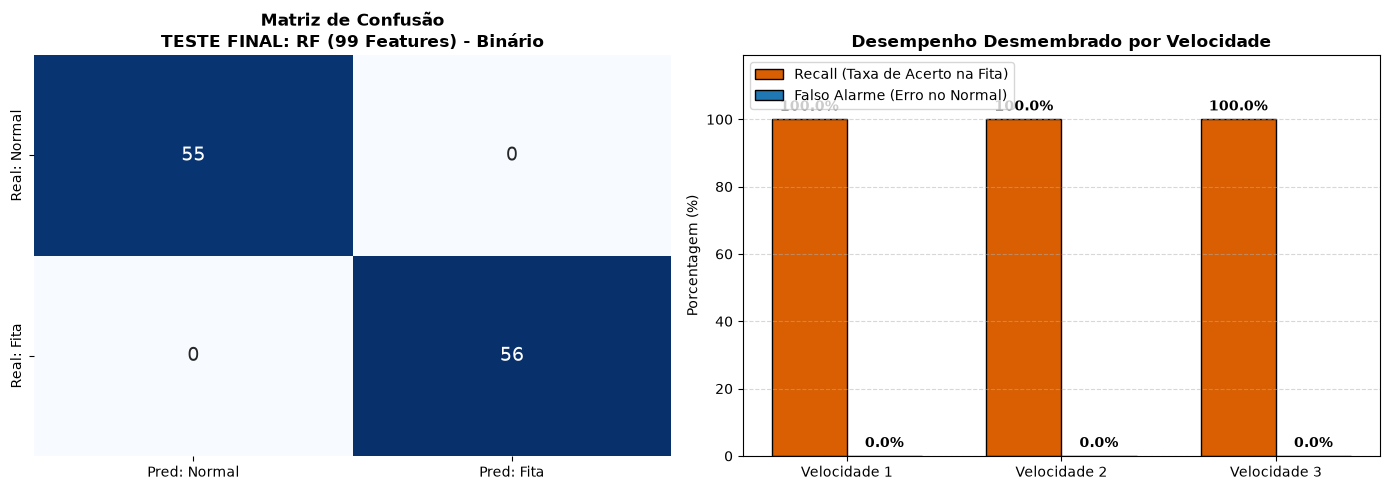

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# 1. Definimos o Pipeline Campeão (Random Forest com 99 Features)
pipeline_campeao_binario = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

print("Treinando o modelo definitivo com 100% dos blocos de Treino...")
# 2. Treinamos o modelo na base inteira de Treino
pipeline_campeao_binario.fit(X_train, y_bin_train)

print("Abrindo o Cofre: Realizando predições nos blocos inéditos de Teste...")
# 3. Fazemos a predição cega no Teste Trancado
y_pred_teste_binario = pipeline_campeao_binario.predict(X_test_locked)

# 4. Extraindo as variáveis do Teste para usar na avaliação (CORREÇÃO AQUI)
vels_teste = meta_test_locked['velocidade'].values
y_bin_test = meta_test_locked['anomalia'].values # <-- Criando a variável que faltava!
y_6_test = meta_test_locked['classe_completa'].values # Já deixamos pronta para a próxima célula

# 5. Acionando as nossas ferramentas de avaliação
avaliar_modelo_detalhado(y_real=y_bin_test, 
                         y_pred=y_pred_teste_binario, 
                         velocidades=vels_teste, 
                         nome_modelo="TESTE FINAL: RF (99 Features) - Tarefa Binária")

plotar_resultados_modelo(y_real=y_bin_test, 
                         y_pred=y_pred_teste_binario, 
                         velocidades=vels_teste, 
                         nome_modelo="TESTE FINAL: RF (99 Features) - Binário")

#### 5.2. O Teste Supremo: Diagnóstico Multiclasse (As 6 Classes Físicas)
Para a manutenção preditiva completa, não basta saber que há um problema; é preciso isolá-lo. Vamos treinar uma nova Random Forest, mas agora o alvo `y` não será apenas `0 ou 1`, e sim o nome exato da classe (ex: `Vel 2 - Fita na Hélice`).

Se o modelo acertar isso nos dados inéditos, ele prova que decifrou completamente a assinatura mecânica e espectral do ventilador.

 TESTE FINAL: RF (99 Features) - TAREFA MULTICLASSE
Acurácia Global (6 Classes): 100.00%

Relatório de Diagnóstico:
                        precision    recall  f1-score   support

Vel 1 - Fita na Hélice       1.00      1.00      1.00        18
        Vel 1 - Normal       1.00      1.00      1.00        20
Vel 2 - Fita na Hélice       1.00      1.00      1.00        18
        Vel 2 - Normal       1.00      1.00      1.00        19
Vel 3 - Fita na Hélice       1.00      1.00      1.00        20
        Vel 3 - Normal       1.00      1.00      1.00        16

              accuracy                           1.00       111
             macro avg       1.00      1.00      1.00       111
          weighted avg       1.00      1.00      1.00       111



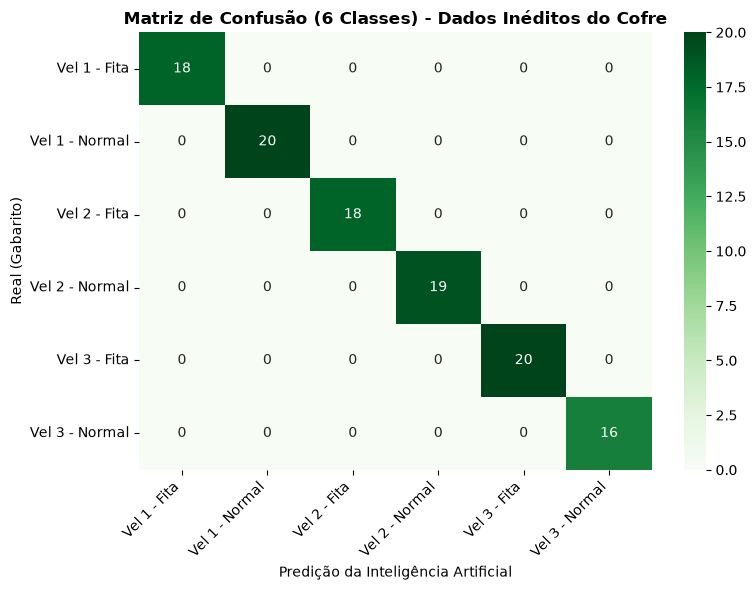

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# 1. Pipeline Campeão, mas agora para a Tarefa Multiclasse
pipeline_campeao_multi = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

# 2. Treinamos com os rótulos de 6 classes (y_6_train)
pipeline_campeao_multi.fit(X_train, y_6_train)

# 3. Predição cega no Teste Trancado
y_pred_teste_multi = pipeline_campeao_multi.predict(X_test_locked)

# 4. Avaliação Multiclasse
acc_multi = accuracy_score(y_6_test, y_pred_teste_multi) * 100
print("==================================================")
print(f" TESTE FINAL: RF (99 Features) - TAREFA MULTICLASSE")
print("==================================================")
print(f"Acurácia Global (6 Classes): {acc_multi:.2f}%\n")
print("Relatório de Diagnóstico:")
print(classification_report(y_6_test, y_pred_teste_multi))

# 5. Plotando a Matriz de Confusão 6x6
fig, ax = plt.subplots(figsize=(8, 6))
classes_ordenadas = sorted(np.unique(y_6_test))
cm_multi = confusion_matrix(y_6_test, y_pred_teste_multi, labels=classes_ordenadas)

sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Greens', ax=ax,
            xticklabels=[c.replace(" na Hélice", "") for c in classes_ordenadas],
            yticklabels=[c.replace(" na Hélice", "") for c in classes_ordenadas])

ax.set_title("Matriz de Confusão (6 Classes) - Dados Inéditos do Cofre", fontweight='bold')
ax.set_ylabel("Real (Gabarito)")
ax.set_xlabel("Predição da Inteligência Artificial")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---

# Seção 3.5 — Testes de estresse da escada de modelos

**Por que esta seção existe.** KNN e Random Forest chegaram a 100% na validação por blocos. Quando dois modelos batem no teto, a comparação entre eles não informa nada. Para aprender algo, precisamos de testes que *possam falhar*.

**Regras:** usamos só o TREINO (`X_train`, `meta_train`, `cv_folds`). O `X_test_locked` **não é tocado** aqui.

**Os 5 testes:**
1. Recall da anomalia e falso alarme **por velocidade** (a métrica primária do plano, ainda não reportada).
2. **Sonda da frequência 1X:** a rotação sozinha separa normal de fita? (detecta confusão de sessão)
3. **Divisão cronológica:** treina no começo da gravação e valida no fim.
4. **Janelas aleatórias × blocos**, com os rótulos reais.
5. **Rótulos embaralhados por bloco**, repetido várias vezes.

**Pré-requisitos já na memória do notebook:** `X_train`, `meta_train`, `y_bin_train`, `y_6_train`, `grupos_train`, `cv_folds`, `modelos`, `resultados_predicoes` e, para o Teste 2, os dados brutos (`df_raw_normal`, `df_raw_fita`, `cortes_normal`, `cortes_fita`).

**Cuidado ao interpretar:** cada validação tem poucos blocos. Trate diferenças pequenas como ruído.

## Teste 1 — Recall da anomalia e falso alarme por velocidade

**O que faz:** usa as predições fora do fold (`resultados_predicoes`) que você já tem e calcula, para cada modelo, o recall da anomalia e a taxa de falso alarme (FPR) separados por velocidade.

**Por quê:** o relatório global esconde onde o modelo falha. A hipótese a verificar é que os modelos simples falham na Vel 1 com fita (a energia dela fica dentro da faixa dos normais). Isso é uma pergunta, não uma conclusão.

**Como ler:**
- *Recall* = das janelas com fita, que fração foi detectada.
- *FPR* = das janelas normais, que fração foi marcada como anomalia (queremos baixo).
- Recall alto na Vel 2 e 3 e baixo na Vel 1 indica que o modelo só enxerga energia absoluta.

,Recall Vel 1,FPR Vel 1,Recall Vel 2,FPR Vel 2,Recall Vel 3,FPR Vel 3,Recall Total,FPR Total
N0: Chute Ingênuo (Tempo),1.000,1.000,1.0,1.0,1.0,1.000,1.000,1.000
N1: Regressão Logística (Tempo),0.408,0.012,1.0,0.0,1.0,0.162,0.804,0.053
N1: Árvore Rasa depth=2 (Tempo),0.000,0.000,1.0,0.0,1.0,0.000,0.670,0.000
N2: KNN k=5 (99 Features),1.000,0.000,1.0,0.0,1.0,0.000,1.000,0.000
N2: Random Forest (99 Features),1.000,0.000,1.0,0.0,1.0,0.000,1.000,0.000


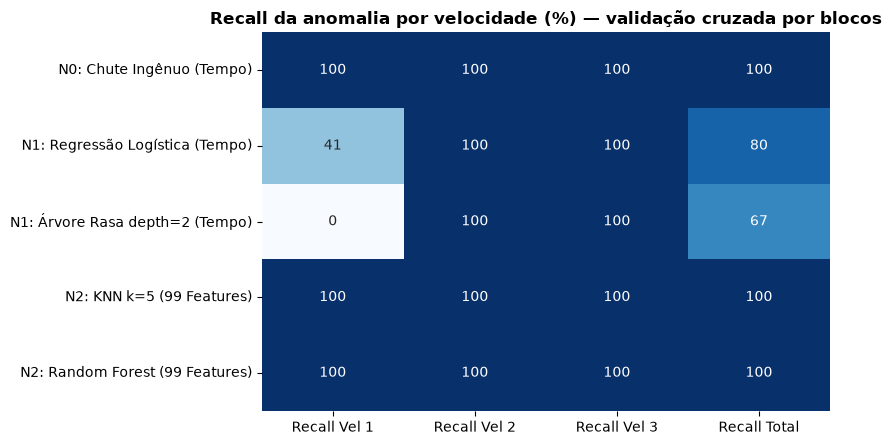

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

vel_train = meta_train['velocidade'].values


def metricas_por_velocidade(y_real, y_pred, vel):
    """Recall da anomalia e FPR por velocidade, mais o total."""
    saida = {}
    for v in [1, 2, 3, 'Total']:
        m = np.ones(len(y_real), dtype=bool) if v == 'Total' else (vel == v)
        anom, norm = (y_real == 1) & m, (y_real == 0) & m
        rot = 'Total' if v == 'Total' else f'Vel {v}'
        saida[f'Recall {rot}'] = ((y_pred == 1) & anom).sum() / anom.sum()
        saida[f'FPR {rot}'] = ((y_pred == 1) & norm).sum() / norm.sum()
    return saida


def tabela_metricas(predicoes, y_real, vel):
    return pd.DataFrame({nome: metricas_por_velocidade(y_real, p, vel) for nome, p in predicoes.items()}).T


def heat_recall(tab, titulo):
    cols = ['Recall Vel 1', 'Recall Vel 2', 'Recall Vel 3', 'Recall Total']
    plt.figure(figsize=(8.5, 0.55 * len(tab) + 1.8))
    sns.heatmap(tab[cols] * 100, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False)
    plt.title(titulo, fontweight='bold')
    plt.tight_layout()
    plt.show()


tab_bloco = tabela_metricas(resultados_predicoes, y_bin_train, vel_train)
display(tab_bloco.round(3))
heat_recall(tab_bloco, "Recall da anomalia por velocidade (%) — validação cruzada por blocos")

## Teste 2 — Sonda da frequência de rotação (1X)

**O que faz:** para cada janela, estima a frequência de rotação (o maior pico entre 8 e 30 Hz, com zero-padding para afinar a resolução) e mostra como ela evolui no tempo. Depois treina um classificador de **uma única regra** (um *stump*) usando *só* essa frequência, dentro de cada velocidade, com os mesmos folds por blocos.

**Por quê:** os dois ensaios podem ter rotações diferentes por motivos que não são a fita (o ensaio com fita começou com o motor já aquecido, e o normal aqueceu durante a gravação). Se a rotação sozinha separar normal de fita, o modelo pode estar usando a sessão, e não o defeito.

**Como ler:**
- *Gráfico:* se as duas cores ocupam faixas de frequência diferentes numa velocidade, os ensaios diferem nela.
- *Tabela:* acerto próximo de 50% = a rotação não distingue as classes. Acerto alto = há confusão de sessão naquela velocidade. Isso não invalida o resultado, mas precisa constar como limitação e justifica novas coletas.

`f1x_hz` é só metadado de diagnóstico e **não entra no modelo**.

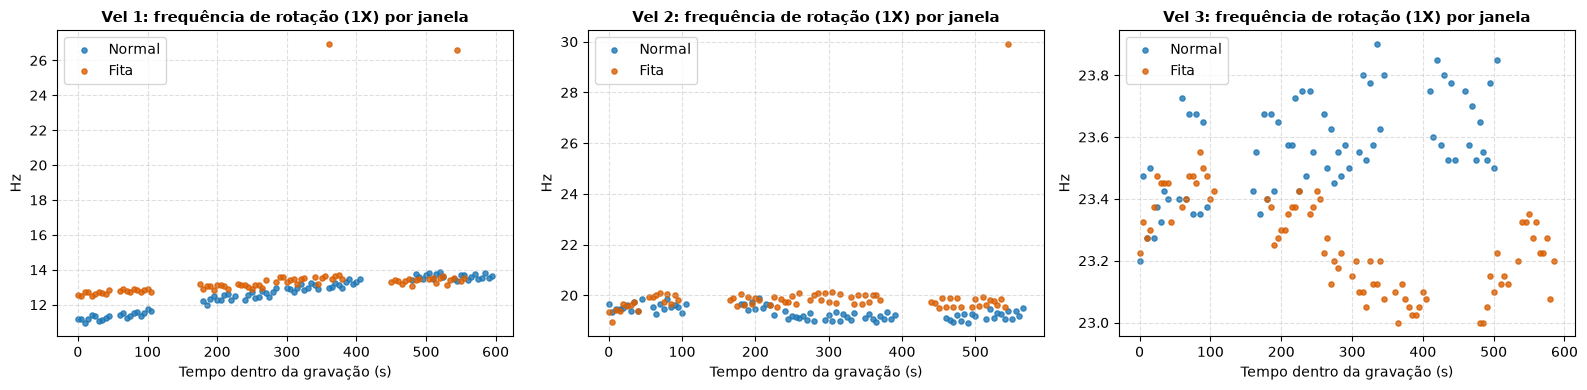

,Velocidade,Acerto só com f1x,Recall anomalia,FPR,Janelas
0,1,0.646,0.934,0.622,158
1,2,0.815,0.851,0.221,151
2,3,0.804,0.938,0.353,148


In [23]:
from sklearn.tree import DecisionTreeClassifier

N_JAN, FATOR_ZP, FS = 5000, 8, 1000                       # janela de 5 s; zero-padding 8x -> ~0,025 Hz
hann = np.hanning(N_JAN)
freqs = np.fft.rfftfreq(N_JAN * FATOR_ZP, d=1 / FS)
faixa_1x = (freqs >= 8) & (freqs <= 30)

arr_normal = df_raw_normal[['x', 'y', 'z']].values        # convertidos uma única vez (mais rápido)
arr_fita = df_raw_fita[['x', 'y', 'z']].values


def freq_1x(sinal_xyz):
    """Frequência do maior pico entre 8 e 30 Hz, somando os espectros dos 3 eixos."""
    esp = 0
    for k in range(3):
        s = sinal_xyz[:, k] - sinal_xyz[:, k].mean()
        esp = esp + np.abs(np.fft.rfft(s * hann, n=N_JAN * FATOR_ZP))
    return freqs[faixa_1x][np.argmax(esp[faixa_1x])]


def f1x_das_janelas(meta):
    f = np.zeros(len(meta))
    for i, (v, a, idx) in enumerate(zip(meta['velocidade'], meta['anomalia'], meta['idx_janela_classe'])):
        arr, cortes = (arr_fita, cortes_fita) if a == 1 else (arr_normal, cortes_normal)
        ini = cortes[v][0] * FS + idx * N_JAN              # mesma posição usada na extração
        f[i] = freq_1x(arr[ini: ini + N_JAN])
    return f


meta_train['f1x_hz'] = f1x_das_janelas(meta_train)

# --- gráfico: rotação ao longo do tempo, por velocidade ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, [1, 2, 3]):
    for a, cor, nome in [(0, '#1f77b4', 'Normal'), (1, '#d95f02', 'Fita')]:
        s = meta_train[(meta_train['velocidade'] == v) & (meta_train['anomalia'] == a)]
        ax.scatter(s['tempo_relativo_s'], s['f1x_hz'], s=14, color=cor, label=nome, alpha=.8)
    ax.set_title(f"Vel {v}: frequência de rotação (1X) por janela", fontweight='bold', fontsize=11)
    ax.set_xlabel("Tempo dentro da gravação (s)"); ax.set_ylabel("Hz")
    ax.grid(True, linestyle='--', alpha=.4); ax.legend()
plt.tight_layout(); plt.show()


# --- sonda: stump usando só f1x, com os folds por blocos, dentro de cada velocidade ---
def sonda_1x(v):
    m = (meta_train['velocidade'] == v).values
    f = meta_train['f1x_hz'].values.reshape(-1, 1)
    pred = np.full(len(y_bin_train), -1)
    for tr, va in cv_folds:
        tr, va = tr[m[tr]], va[m[va]]
        stump = DecisionTreeClassifier(max_depth=1, random_state=42).fit(f[tr], y_bin_train[tr])
        pred[va] = stump.predict(f[va])
    y, p = y_bin_train[m], pred[m]
    return {'Velocidade': v,
            'Acerto só com f1x': (y == p).mean(),
            'Recall anomalia': ((p == 1) & (y == 1)).sum() / (y == 1).sum(),
            'FPR': ((p == 1) & (y == 0)).sum() / (y == 0).sum(),
            'Janelas': int(m.sum())}


display(pd.DataFrame([sonda_1x(v) for v in [1, 2, 3]]).round(3))

## Teste 3 — Divisão cronológica (treina no começo, valida no fim)

**O que faz:** treina cada modelo da escada nos blocos iniciais de cada gravação (blocos 0 a 6) e valida nos blocos finais (8 e 9). O bloco 7 pertence ao teste trancado e fica **fora dos dois lados**, funcionando como um fosso natural no tempo.

**Por quê:** na validação cruzada por blocos, os blocos de validação têm vizinhos de treino de ambos os lados no tempo, e a deriva térmica pode ajudar o modelo. Aqui o modelo precisa *extrapolar* para a parte final da gravação (motor mais quente).

**Como ler:** compare com o Teste 1.
- Queda pequena = o modelo não depende tanto da deriva.
- Queda grande = parte do desempenho vinha de vizinhança temporal ou do estado térmico.
- A queda também pode ter causas que não são a fita (o motor realmente mudou), por isso este é um **teste de estresse, não uma nota**.
- A validação tem só 2 blocos por classe, então os números são grosseiros.

Treino cronológico: 337 janelas | Validação final: 120 janelas


,Recall Vel 1,FPR Vel 1,Recall Vel 2,FPR Vel 2,Recall Vel 3,FPR Vel 3,Recall Total,FPR Total
N0: Chute Ingênuo (Tempo),1.0,1.000,1.0,1.0,1.0,1.000,1.000,1.000
N1: Regressão Logística (Tempo),0.5,0.045,1.0,0.0,1.0,0.056,0.833,0.033
N1: Árvore Rasa depth=2 (Tempo),0.0,0.000,1.0,0.0,1.0,0.000,0.667,0.000
N2: KNN k=5 (99 Features),1.0,0.000,1.0,0.0,1.0,0.000,1.000,0.000
N2: Random Forest (99 Features),1.0,0.000,1.0,0.0,1.0,0.000,1.000,0.000


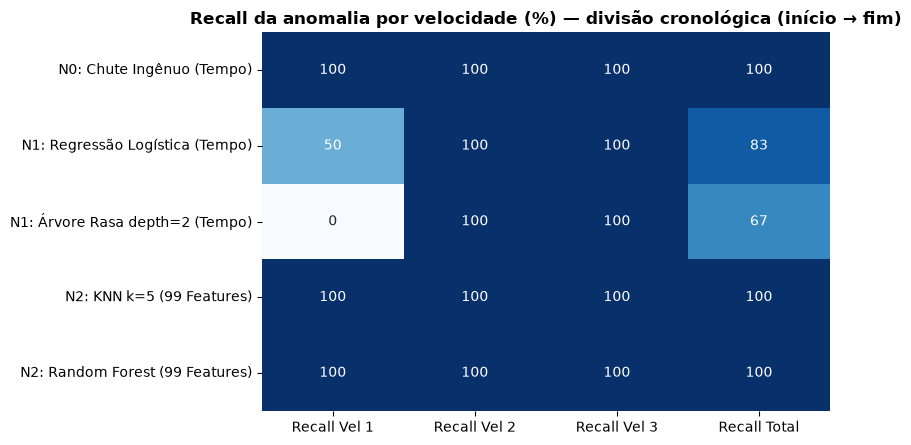

In [24]:
from sklearn.base import clone

tr_cron = (meta_train['bloco_local'] <= 6).values
va_cron = (meta_train['bloco_local'] >= 8).values
print(f"Treino cronológico: {tr_cron.sum()} janelas | Validação final: {va_cron.sum()} janelas")

pred_cron = {}
for nome, (pipe, X_dados) in modelos.items():
    p = clone(pipe).fit(X_dados[tr_cron], y_bin_train[tr_cron])
    pred_cron[nome] = p.predict(X_dados[va_cron])

tab_cron = tabela_metricas(pred_cron, y_bin_train[va_cron], vel_train[va_cron])
display(tab_cron.round(3))
heat_recall(tab_cron, "Recall da anomalia por velocidade (%) — divisão cronológica (início → fim)")

## Teste 4 — Janelas aleatórias × blocos (rótulos reais)

**O que faz:** repete a validação de cada modelo de duas formas e compara o acerto: (a) por **blocos** (o que já fizemos) e (b) por **janelas sorteadas** (o jeito ingênuo, estratificado pelas 6 classes).

**Por quê:** mostra, nos *seus* dados, quanto a vizinhança temporal infla a nota.

**Como ler:**
- Modelos fracos tendem a mostrar a diferença. Se a versão ingênua der bem mais que a por blocos, o vazamento é real e justifica o cuidado.
- Modelos já no teto (100%) não mostram diferença, e isso **não** significa que o vazamento não existe: apenas que não há margem para aparecer. O Teste 5 é mais sensível para isso.

,Acerto por blocos,Acerto por janelas (ingênuo)
Modelo,,
N0: Chute Ingênuo (Tempo),50.3,50.3
N1: Regressão Logística (Tempo),87.5,88.0
N1: Árvore Rasa depth=2 (Tempo),83.4,83.4
N2: KNN k=5 (99 Features),100.0,100.0
N2: Random Forest (99 Features),100.0,100.0


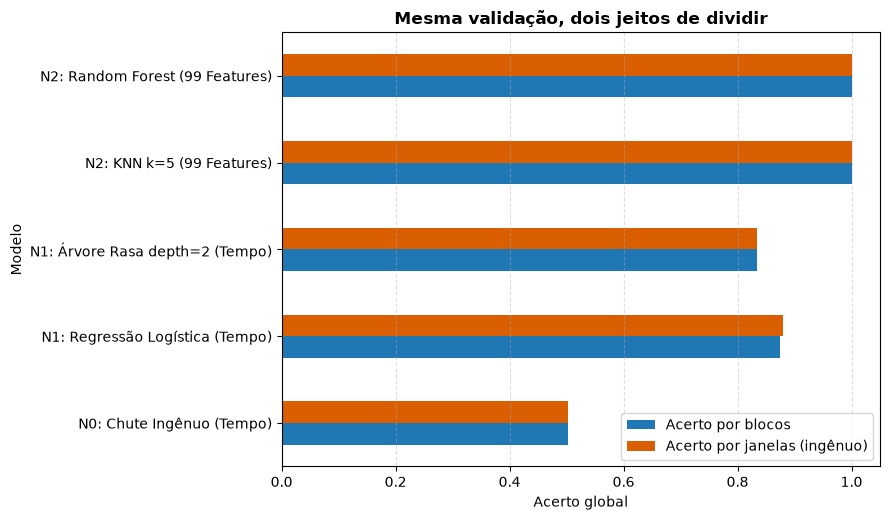

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv_janela = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=42).split(X_train, y_6_train))

linhas = []
for nome, (pipe, X_dados) in modelos.items():
    p_janela = cross_val_predict(pipe, X_dados, y_bin_train, cv=cv_janela)
    linhas.append({'Modelo': nome,
                   'Acerto por blocos': (resultados_predicoes[nome] == y_bin_train).mean(),
                   'Acerto por janelas (ingênuo)': (p_janela == y_bin_train).mean()})
tab_vaza = pd.DataFrame(linhas).set_index('Modelo')
display((tab_vaza * 100).round(1))

ax = tab_vaza.plot(kind='barh', figsize=(9, 0.7 * len(tab_vaza) + 1.8), color=['#1f77b4', '#d95f02'])
ax.set_xlim(0, 1.05); ax.set_xlabel('Acerto global')
ax.set_title("Mesma validação, dois jeitos de dividir", fontweight='bold')
ax.grid(True, axis='x', linestyle='--', alpha=.4)
plt.tight_layout(); plt.show()

## Teste 5 — Rótulos embaralhados por bloco

**O que faz:** troca os rótulos entre os 48 blocos de treino (cada bloco inteiro recebe o rótulo de outro bloco, sorteado) e roda a validação de novo, repetindo várias vezes. Faz isso com os dois jeitos de dividir: por **blocos** e por **janelas**.

**Por quê:** com rótulos sem relação com os sinais, um pipeline correto deve cair para o acaso (~50% no binário). Já uma divisão por janelas continua "acertando", porque a vizinha do mesmo bloco, que está no treino, carrega o mesmo rótulo falso. Isso mede o vazamento temporal.

**Como ler:**
- Histograma azul (por blocos) centrado perto de 50% = pipeline sem vazamento temporal.
- Histograma laranja (por janelas) muito acima de 50% = o vazamento que o plano evita.
- A linha tracejada é o acerto com os rótulos **reais** por blocos. Se ela fica bem à direita da distribuição azul, o sinal é real dentro da sessão.
- Este teste **não detecta** confusão de sessão (a classe é a própria gravação). Para isso servem o Teste 2 e uma sessão nova.
- Com poucas repetições, o menor p-valor possível é 1/(N+1).

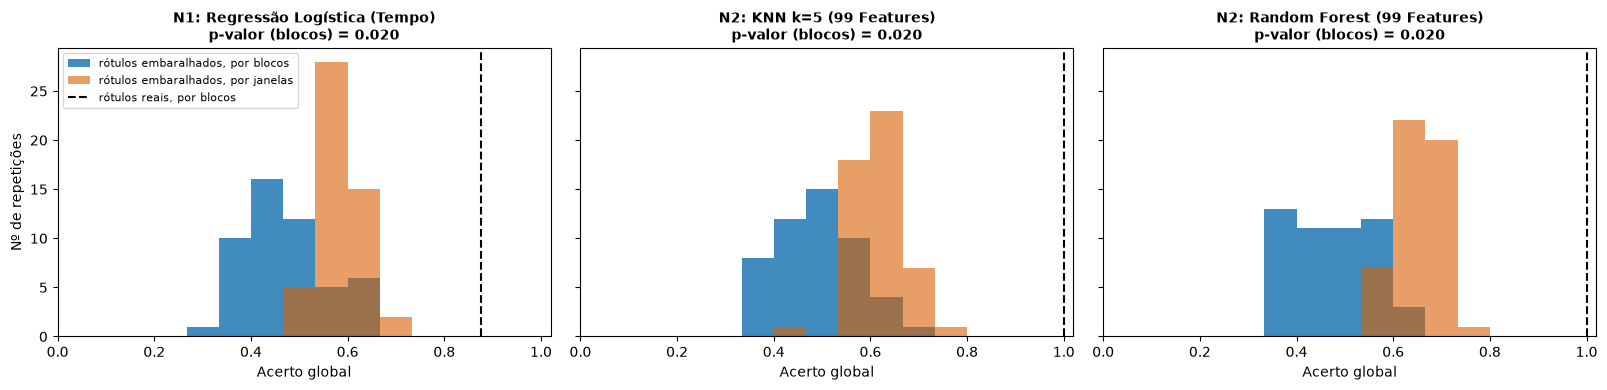

,média por blocos,desvio por blocos,média por janelas
N1: Regressão Logística (Tempo),47.1,8.2,58.5
N2: KNN k=5 (99 Features),48.8,8.1,61.9
N2: Random Forest (99 Features),47.5,8.5,65.2


In [25]:
N_REP = 50                                                   # aumente para 100 se o tempo permitir
escolhidos = ['N1: Regressão Logística (Tempo)', 'N2: KNN k=5 (99 Features)', 'N2: Random Forest (99 Features)']

blocos = pd.DataFrame({'bloco': grupos_train, 'y': y_bin_train}).groupby('bloco')['y'].first()   # 48 blocos
rng = np.random.default_rng(42)
nulo = {n: {'bloco': [], 'janela': []} for n in escolhidos}

for rep in range(N_REP):
    mapa = dict(zip(blocos.index, rng.permutation(blocos.values)))       # embaralha ENTRE blocos
    y_perm = pd.Series(grupos_train).map(mapa).values
    cv_naive = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=rep).split(X_train, y_6_train))
    for nome in escolhidos:
        pipe, X_dados = modelos[nome]
        p_b = cross_val_predict(pipe, X_dados, y_perm, cv=cv_folds)
        p_j = cross_val_predict(pipe, X_dados, y_perm, cv=cv_naive)
        nulo[nome]['bloco'].append((p_b == y_perm).mean())
        nulo[nome]['janela'].append((p_j == y_perm).mean())

fig, axes = plt.subplots(1, len(escolhidos), figsize=(5.4 * len(escolhidos), 4), sharey=True)
for ax, nome in zip(axes, escolhidos):
    real = (resultados_predicoes[nome] == y_bin_train).mean()
    nb = np.array(nulo[nome]['bloco'])
    p_valor = (np.sum(nb >= real) + 1) / (N_REP + 1)
    ax.hist(nulo[nome]['bloco'], bins=15, range=(0, 1), alpha=.85, color='#1f77b4', label='rótulos embaralhados, por blocos')
    ax.hist(nulo[nome]['janela'], bins=15, range=(0, 1), alpha=.6, color='#d95f02', label='rótulos embaralhados, por janelas')
    ax.axvline(real, color='k', ls='--', label='rótulos reais, por blocos')
    ax.set_title(f"{nome}\np-valor (blocos) = {p_valor:.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel('Acerto global'); ax.set_xlim(0, 1.02)
axes[0].set_ylabel('Nº de repetições'); axes[0].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

resumo = pd.DataFrame({n: {'média por blocos': np.mean(v['bloco']), 'desvio por blocos': np.std(v['bloco']),
                           'média por janelas': np.mean(v['janela'])} for n, v in nulo.items()}).T
display((resumo * 100).round(1))

# Seção 3.6 — O que o Random Forest está usando? (importância por grupos de features)

**Por que esta seção existe.** O Random Forest chegou a 100% (com 99 features e também só com as 9 de tempo). Antes de aceitar isso, queremos saber *de onde* vem a informação. Se o desempenho depender de uma única coluna ou de um único grupo, vale desconfiar.

**Duas perguntas diferentes:**
1. **Necessidade:** se eu embaralhar *um grupo inteiro* de features nos dados de validação, o desempenho cai quanto? (importância por permutação em grupos)
2. **Suficiência:** se eu treinar o modelo *só com um grupo*, ele ainda acerta? (modelo de um grupo só)

**Por que em grupos e não coluna a coluna:** colunas muito correlacionadas (por exemplo `std_x` e `pico_x`, ou bandas vizinhas da FFT) dividem a importância entre si, e embaralhar uma só faz as duas parecerem irrelevantes. Embaralhar o grupo todo, com a **mesma permutação** nas colunas dele, mede o efeito real de cada domínio.

**Regras:** só treino e folds por blocos (`X_train`, `y_bin_train`, `cv_folds`). O cofre não é tocado.

**Cuidado ao interpretar:** estes testes dizem *o que o modelo usa*, não se o que ele usa é o defeito físico ou a sessão. Para isso, a sessão nova continua sendo o teste decisivo.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict

cols_fft = [c for c in X_train.columns if c.startswith('fft_')]


def banda_inicial(c):
    """'fft_015_025Hz_x' -> 15 (início da faixa, em Hz)."""
    return int(c.split('_')[1])


grupos = {
    'Tempo X': ['std_x', 'kurt_x', 'pico_x'],
    'Tempo Y': ['std_y', 'kurt_y', 'pico_y'],
    'Tempo Z': ['std_z', 'kurt_z', 'pico_z'],
    'FFT 5-15 Hz (rotação 1X)': [c for c in cols_fft if banda_inicial(c) == 5],
    'FFT 15-105 Hz (harmônicas baixas)': [c for c in cols_fft if 15 <= banda_inicial(c) < 105],
    'FFT 105-305 Hz (altas e rede)': [c for c in cols_fft if banda_inicial(c) >= 105],
}

todas = [c for cols in grupos.values() for c in cols]
assert sorted(todas) == sorted(X_train.columns), "Algum grupo está faltando ou repetido!"
print({g: len(c) for g, c in grupos.items()})

{'Tempo X': 3, 'Tempo Y': 3, 'Tempo Z': 3, 'FFT 5-15 Hz (rotação 1X)': 3, 'FFT 15-105 Hz (harmônicas baixas)': 27, 'FFT 105-305 Hz (altas e rede)': 60}


## Necessidade — importância por permutação em grupos

**O que faz:** para cada fold, treina o Random Forest no treino do fold e, na validação, embaralha um grupo de cada vez (mesma permutação em todas as colunas do grupo, 10 repetições) e mede a **queda** em dois números: F1 macro (geral) e recall da anomalia na Vel 1 (onde a informação é mais sutil).

**Como ler:**
- Queda grande = o modelo depende daquele grupo.
- Queda perto de zero = a informação também está em outro grupo (redundância). Isso é comum aqui e não é defeito.
- O traço preto é a variação entre folds e repetições. Quedas menores que isso são ruído.
- O painel da direita repete o teste para o modelo que usa **só as 9 features de tempo**.

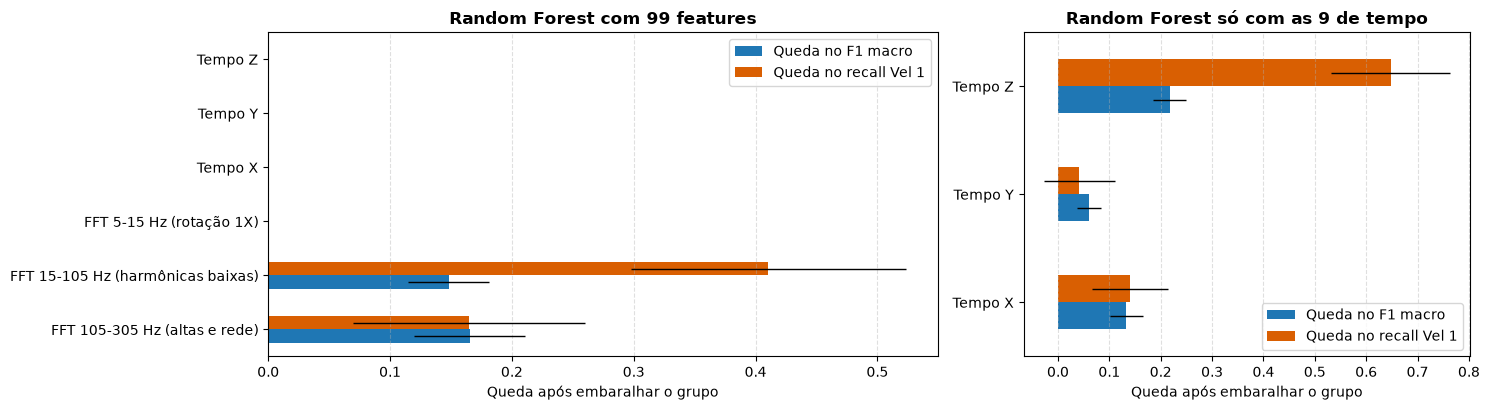

In [27]:
def recall_vel(y, p, vel, v=1):
    m = (vel == v) & (y == 1)
    return ((p == 1) & m).sum() / m.sum() if m.sum() else np.nan


def importancia_por_grupos(pipe, X, y, vel, folds, grupos, n_rep=10, seed=0):
    rng = np.random.default_rng(seed)
    linhas = []
    for k, (tr, va) in enumerate(folds):
        modelo = clone(pipe).fit(X.iloc[tr], y[tr])
        Xva, yva, vva = X.iloc[va], y[va], vel[va]
        p0 = modelo.predict(Xva)
        base_f1, base_v1 = f1_score(yva, p0, average='macro'), recall_vel(yva, p0, vva)
        for g, cols in grupos.items():
            for _ in range(n_rep):
                Xp = Xva.copy()
                Xp[cols] = Xva[cols].values[rng.permutation(len(Xva))]      # mesma permutação no grupo todo
                p = modelo.predict(Xp)
                linhas.append({'grupo': g, 'fold': k,
                               'Queda no F1 macro': base_f1 - f1_score(yva, p, average='macro'),
                               'Queda no recall Vel 1': base_v1 - recall_vel(yva, p, vva)})
    return pd.DataFrame(linhas)


vel_train = meta_train['velocidade'].values
pipe_rf = Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))])
grupos_tempo = {g: c for g, c in grupos.items() if g.startswith('Tempo')}

imp_99 = importancia_por_grupos(pipe_rf, X_train, y_bin_train, vel_train, cv_folds, grupos)
imp_tp = importancia_por_grupos(pipe_rf, X_train[sum(grupos_tempo.values(), [])], y_bin_train, vel_train, cv_folds, grupos_tempo)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
for ax, imp, titulo in [(axes[0], imp_99, 'Random Forest com 99 features'), (axes[1], imp_tp, 'Random Forest só com as 9 de tempo')]:
    media = imp.groupby('grupo')[['Queda no F1 macro', 'Queda no recall Vel 1']].mean()
    erro = imp.groupby('grupo')[['Queda no F1 macro', 'Queda no recall Vel 1']].std()
    media.plot(kind='barh', xerr=erro, ax=ax, color=['#1f77b4', '#d95f02'], error_kw={'ecolor': 'black', 'lw': 1})
    ax.set_title(titulo, fontweight='bold'); ax.set_xlabel('Queda após embaralhar o grupo'); ax.set_ylabel('')
    ax.grid(True, axis='x', linestyle='--', alpha=.4)
plt.tight_layout(); plt.show()

## Suficiência — um modelo para cada grupo, sozinho

**O que faz:** treina um Random Forest usando *apenas* as colunas de um grupo, com os mesmos folds por blocos, e mostra o recall da anomalia por velocidade e o falso alarme.

**Por quê:** complementa o teste anterior. Um grupo pode não fazer falta (porque outros cobrem) e mesmo assim ser suficiente sozinho, ou o contrário.

**Como ler:**
- Um grupo que sozinho chega perto de 100% em todas as velocidades é suficiente para detectar *dentro da sessão*.
- Se **só** o grupo da rotação 1X (5–15 Hz) já separa a Vel 1, lembre que essa faixa mede a amplitude do 1X: o desbalanceamento a aumenta, mas a diferença de sessão (temperatura, fixação) também pode. Esse é um sinal para priorizar a sessão nova.
- Se os grupos de **tempo** bastam, o modelo pode ser bem mais simples que o de 99 features (e mais barato de calcular na produção), desde que a sessão nova confirme.

,Recall Vel 1,Recall Vel 2,Recall Vel 3,FPR total,F1 macro
Tempo X,0.737,1.000,1.0,0.128,0.893
Tempo Y,0.816,1.000,1.0,0.022,0.958
Tempo Z,0.947,1.000,1.0,0.018,0.982
FFT 5-15 Hz (rotação 1X),0.908,0.959,0.9,0.062,0.930
FFT 15-105 Hz (harmônicas baixas),1.000,1.000,1.0,0.000,1.000
FFT 105-305 Hz (altas e rede),1.000,1.000,1.0,0.000,1.000


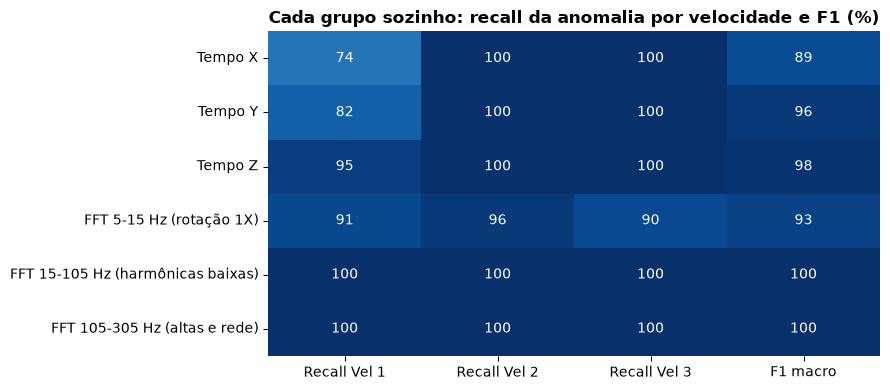

In [28]:
def metricas_grupo(y, p, vel):
    saida = {}
    for v in [1, 2, 3]:
        m = vel == v
        saida[f'Recall Vel {v}'] = ((p == 1) & (y == 1) & m).sum() / ((y == 1) & m).sum()
    saida['FPR total'] = ((p == 1) & (y == 0)).sum() / (y == 0).sum()
    saida['F1 macro'] = f1_score(y, p, average='macro')
    return saida


linhas = {}
for g, cols in grupos.items():
    p = cross_val_predict(pipe_rf, X_train[cols], y_bin_train, cv=cv_folds)
    linhas[g] = metricas_grupo(y_bin_train, p, vel_train)
tab_suf = pd.DataFrame(linhas).T
display(tab_suf.round(3))

plt.figure(figsize=(9, 4))
sns.heatmap(tab_suf[['Recall Vel 1', 'Recall Vel 2', 'Recall Vel 3', 'F1 macro']] * 100, annot=True, fmt='.0f',
            cmap='Blues', vmin=0, vmax=100, cbar=False)
plt.title("Cada grupo sozinho: recall da anomalia por velocidade e F1 (%)", fontweight='bold')
plt.tight_layout(); plt.show()